In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

# Q1

In [39]:
df = pd.read_csv("MavenRail.csv")
print(df.info())
print(df.head())

<class 'pandas.DataFrame'>
RangeIndex: 30686 entries, 0 to 30685
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   Payment.Method     30686 non-null  str  
 1   Railcard           10359 non-null  str  
 2   Ticket.Class       30686 non-null  str  
 3   Ticket.Type        30686 non-null  str  
 4   Price              30686 non-null  int64
 5   Departure.Station  30686 non-null  str  
 6   Arrival.Station    30686 non-null  str  
 7   Departure          30683 non-null  str  
 8   Scheduled.Arrival  30682 non-null  str  
 9   Actual.Arrival     28851 non-null  str  
 10  Journey.Status     30686 non-null  str  
 11  Reason.for.Delay   4121 non-null   str  
 12  Refund.Request     30686 non-null  str  
dtypes: int64(1), str(12)
memory usage: 6.5 MB
None
  Payment.Method Railcard Ticket.Class Ticket.Type  Price  \
0    Contactless    Adult     Standard     Advance     43   
1    Credit Card    Adult     Standard

# Q2

In [40]:
print("Combined:\n",
      df["Price"].describe())
print("First Class:\n",
      df[df["Ticket.Class"]=="First Class"]["Price"].describe())
print("Standard:\n",
      df[df["Ticket.Class"]=="Standard"]["Price"].describe())

Combined:
 count    30686.000000
mean        23.212964
std         29.979996
min          1.000000
25%          5.000000
50%         11.000000
75%         34.000000
max        267.000000
Name: Price, dtype: float64
First Class:
 count    2962.000000
mean       48.530722
std        40.963694
min         4.000000
25%        15.000000
50%        41.000000
75%        59.000000
max       267.000000
Name: Price, dtype: float64
Standard:
 count    27724.000000
mean        20.508044
std         27.199347
min          1.000000
25%          4.000000
50%         10.000000
75%         23.000000
max        171.000000
Name: Price, dtype: float64


In [41]:
print("First class null: ", df[df["Ticket.Class"]=="First Class"]["Price"].isna().sum())
print("Standard null: ", df[df["Ticket.Class"]=="Standard"]["Price"].isna().sum())

First class null:  0
Standard null:  0


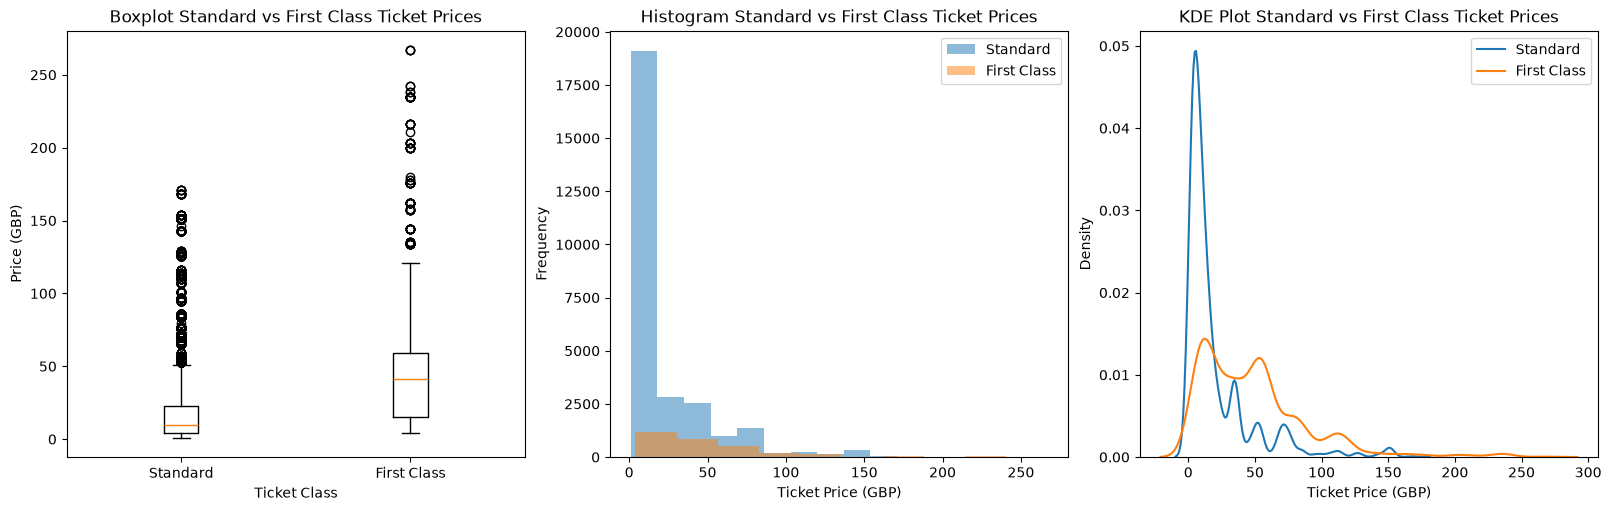

In [42]:
fig, axs = plt.subplots(1,3, figsize=(16,5), layout="constrained")
axs[0].boxplot([df[df["Ticket.Class"]=="Standard"]["Price"], 
                df[df["Ticket.Class"]=="First Class"]["Price"]], 
               tick_labels=["Standard", "First Class"])
axs[0].set_title("Boxplot Standard vs First Class Ticket Prices")
axs[0].set_xlabel("Ticket Class")
axs[0].set_ylabel("Price (GBP)")

axs[1].hist(df[df["Ticket.Class"]=="Standard"]["Price"], 
            label="Standard", alpha=0.5)
axs[1].hist(df[df["Ticket.Class"]=="First Class"]["Price"], 
            label="First Class", alpha=0.5)
axs[1].set_title("Histogram Standard vs First Class Ticket Prices")
axs[1].set_xlabel("Ticket Price (GBP)")
axs[1].set_ylabel("Frequency")
axs[1].legend()

sns.kdeplot(df[df["Ticket.Class"]=="Standard"]["Price"], 
            label="Standard", ax=axs[2])
sns.kdeplot(df[df["Ticket.Class"]=="First Class"]["Price"], 
            label="First Class", ax=axs[2])
axs[2].set_title("KDE Plot Standard vs First Class Ticket Prices")
axs[2].set_xlabel("Ticket Price (GBP)")
axs[2].set_ylabel("Density")
axs[2].legend()

plt.savefig("ticket_price_distributions.svg")
plt.show()

# Q3

In [43]:
def is_medium_price(value, lowbound=10, highbound=30):
    return 1 if lowbound<value and value<=highbound else 0

df["MediumPrice"] = df["Price"].apply(lambda x: is_medium_price(x))
df["Refund.Request"] = df["Refund.Request"].apply(lambda x: 1 if x=="Yes" else 0)

In [44]:
# And focusing on !="On Time" only
df_late = df[df["Journey.Status"]!="On Time"]

In [45]:
logreg = sm.Logit(df_late["Refund.Request"], sm.add_constant(df_late["MediumPrice"])).fit()
print(logreg.summary())

Optimization terminated successfully.
         Current function value: 0.577033
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:         Refund.Request   No. Observations:                 4121
Model:                          Logit   Df Residuals:                     4119
Method:                           MLE   Df Model:                            1
Date:                Mon, 23 Nov 2026   Pseudo R-squ.:                0.003307
Time:                        12:43:38   Log-Likelihood:                -2378.0
converged:                       True   LL-Null:                       -2385.8
Covariance Type:            nonrobust   LLR p-value:                 7.124e-05
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
const          -1.0841      0.040    -27.402      0.000      -1.162      -1.007
MediumPrice     0.3541    

In [46]:
### Prediction should reflect P(Refund|Not MediumPrice) vs P(refund|MediumPrice)
print(df_late[["MediumPrice", "Refund.Request"]].groupby("MediumPrice").mean())

             Refund.Request
MediumPrice                
0                  0.252734
1                  0.325203


In [47]:
# Predicting with the model:
print(logreg.predict(sm.add_constant([0,1])))

[0.25273426 0.32520325]


In [48]:
# Predicting by calculating with coefficients:
p_not_MediumPrice = 1/(1 + np.exp(-(-1.0841 + 0.3541*0)))
p_MediumPrice = 1/(1 + np.exp(-(-1.0841 + 0.3541*1)))

print([p_not_MediumPrice, p_MediumPrice])

[np.float64(0.25273091415002935), np.float64(0.3251947274176865)]
